## Author: Gabriel Vance
## Class: DSC550 - Data Mining
## Professor: Dr. Brett Werner
## Date: November 15, 2025

# Purpose: This notebook performs the tasks outlined in Week 9 & 10 Assignment - TSA Complaints. For this exercise we will be utilizing python/notebooks to visualize datasets pertaining to TSA complaints.


Medium: PDF report generated for the White House Press Secretary
Audience: The report will be used by the White House Press Secretary in addressing the nation about TSA complaints.
Call to Action: Post-pandemic TSA complaints are higher than pre-pandemic complaints. We are aware of the increase and will be taking measures to improve customer satisfaction and provide a more accomodationg experience.

In the years leading up to the pandemic, the nationwide complains hovered between the 6,000 to 11,000 range. While a decrease would've been a relief to most travelers, this appeared to be our normal range.

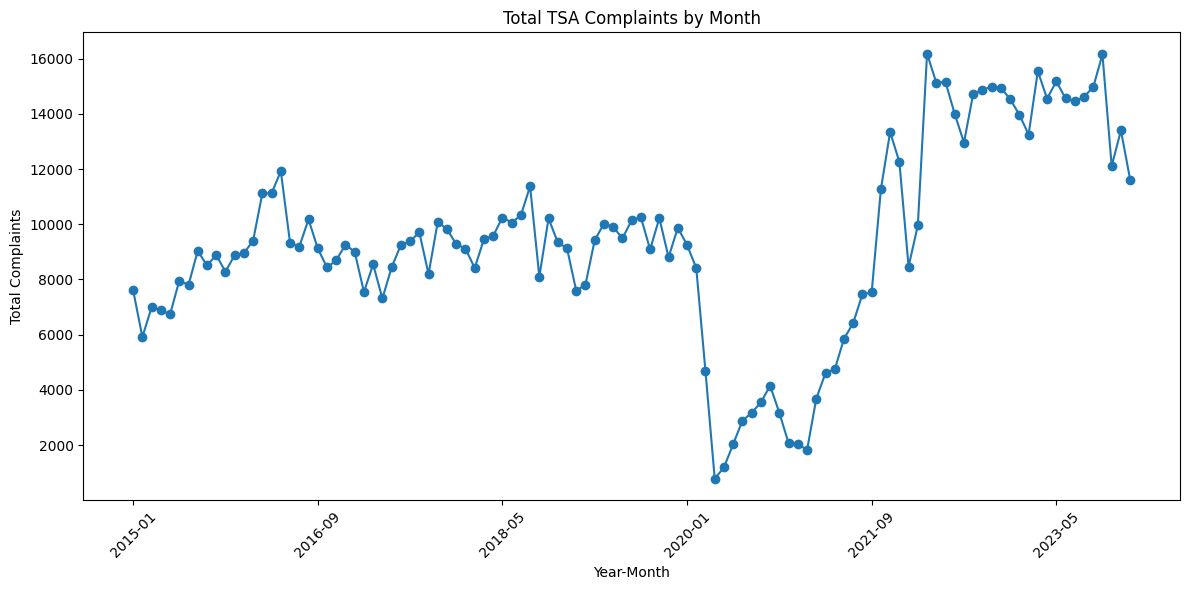

The dip in 2020 was largely related to low rates of travel due to the pandemic. But after a recovery in air travel, our new normal range is 13,000 to 15,000. The administration realizes this is unacceotable and is taking action to improve traveler experience. First, we recognize the majority of complaints come from our expedited screening program.

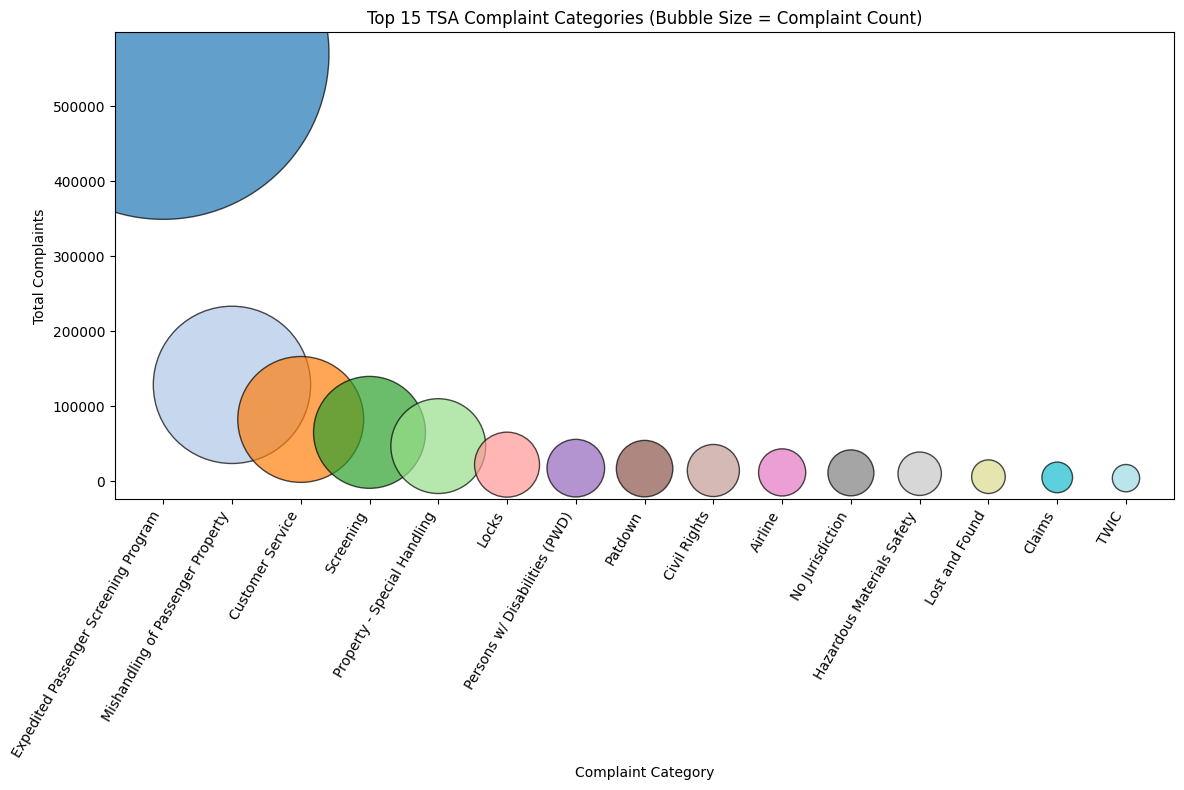

When examining which aiports have the most complaints, we do not see a 

# Code

In [106]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from matplotlib import MatplotlibDeprecationWarning
import plotly.express as px

# Jupyter display tweaks
# from IPython.display import display, HTML

# Suppress warnings for cleaner output
import os

# Suppress DeprecationWarning and TqdmWarning specifically
warnings.filterwarnings("ignore", category=DeprecationWarning)
os.environ["TQDM_DISABLE"] = "1"



# from IPython.core.display import display, HTML

# display(HTML("<style>.container { width:100% !important; }</style>"))
# Ensure that all code cells are fully visible without scrolling


warnings.filterwarnings("ignore", category=MatplotlibDeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

#### First we will read in data

In [107]:
iata_icao  = pd.read_csv('iata-icao.csv')
complaints_by_subcategory  = pd.read_csv('complaints-by-subcategory.csv')
iata_complaints_by_category_icao  = pd.read_csv('complaints-by-category.csv')
complaints_by_airport  = pd.read_csv('complaints-by-airport.csv')

## Visualization 1 – Spatial / Choropleth Map
- **Data Sources:** `complaints-by-airport.csv`, `iata-icao.csv`  
- **Goal:** Plot the top 10 airports by total complaint count as geospatial map points.

In [108]:
# Aggregate complaints per airport
complaints_airport_totals = (
    complaints_by_airport
    .groupby('airport', as_index=False)['count']
    .sum()
    .rename(columns={'count': 'total_complaints'})
)

# Join with location data
airports_with_complaints = complaints_airport_totals.merge(
    iata_icao,
    left_on='airport',  # IATA code from complaints
    right_on='iata',    # IATA from iata_icao
    how='left'
)


# Keep only US airports and valid coordinates
us_airports = (
    airports_with_complaints
    [airports_with_complaints['country_code'] == 'US']
    .dropna(subset=['latitude', 'longitude'])
)

# Find top 10 airports by complaints
us_top_airports = (
    us_airports
    .sort_values('total_complaints', ascending=False) # sort by complaints and take top 10
    .head(10)
)


fig = px.scatter_geo(
    us_top_airports,
    lat='latitude',
    lon='longitude',
    scope='usa',                          # focus on USA only
    projection='albers usa',
    size='total_complaints',
    color='total_complaints',             # color by complaints too
    hover_name='airport_y',               # airport name from iata_icao
    hover_data=['iata', 'total_complaints', 'region_name'],
    title=f'Top 10 US Airports by Total Complaints (from complaints-by-airport.csv & iata-icao.csv)'
)
fig.show()


## Visualization 2 – Bar Chart of Complaints for Top 10 Airports
- **Data Source:** `complaints-by-category.csv`  
- **Goal:** Show which complaint categories are most frequent and compare totals across the top airports.

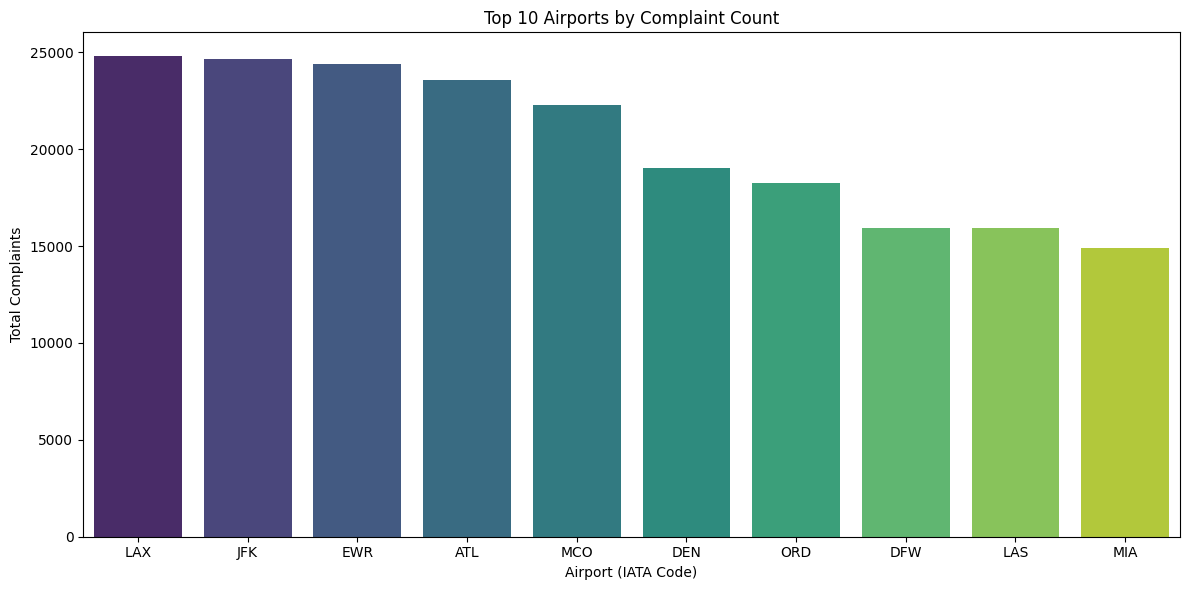

In [109]:
# Aggregate total complaints per airport
airport_totals = (
    complaints_by_airport
    .groupby('airport')['count']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))
sns.barplot(x=airport_totals.index, y=airport_totals.values, palette='viridis')
plt.title('Top 10 Airports by Complaint Count')
plt.xlabel('Airport (IATA Code)')
plt.ylabel('Total Complaints')
plt.tight_layout()
plt.show()

## Visualization 3 – Heatmap of Complaints vs. Airports
- **Data Source:** `complaints-by-category.csv`  
- **Goal:** Visualize intensity patterns by mapping complaint categories (rows) against airports (columns) to identify hot spots.

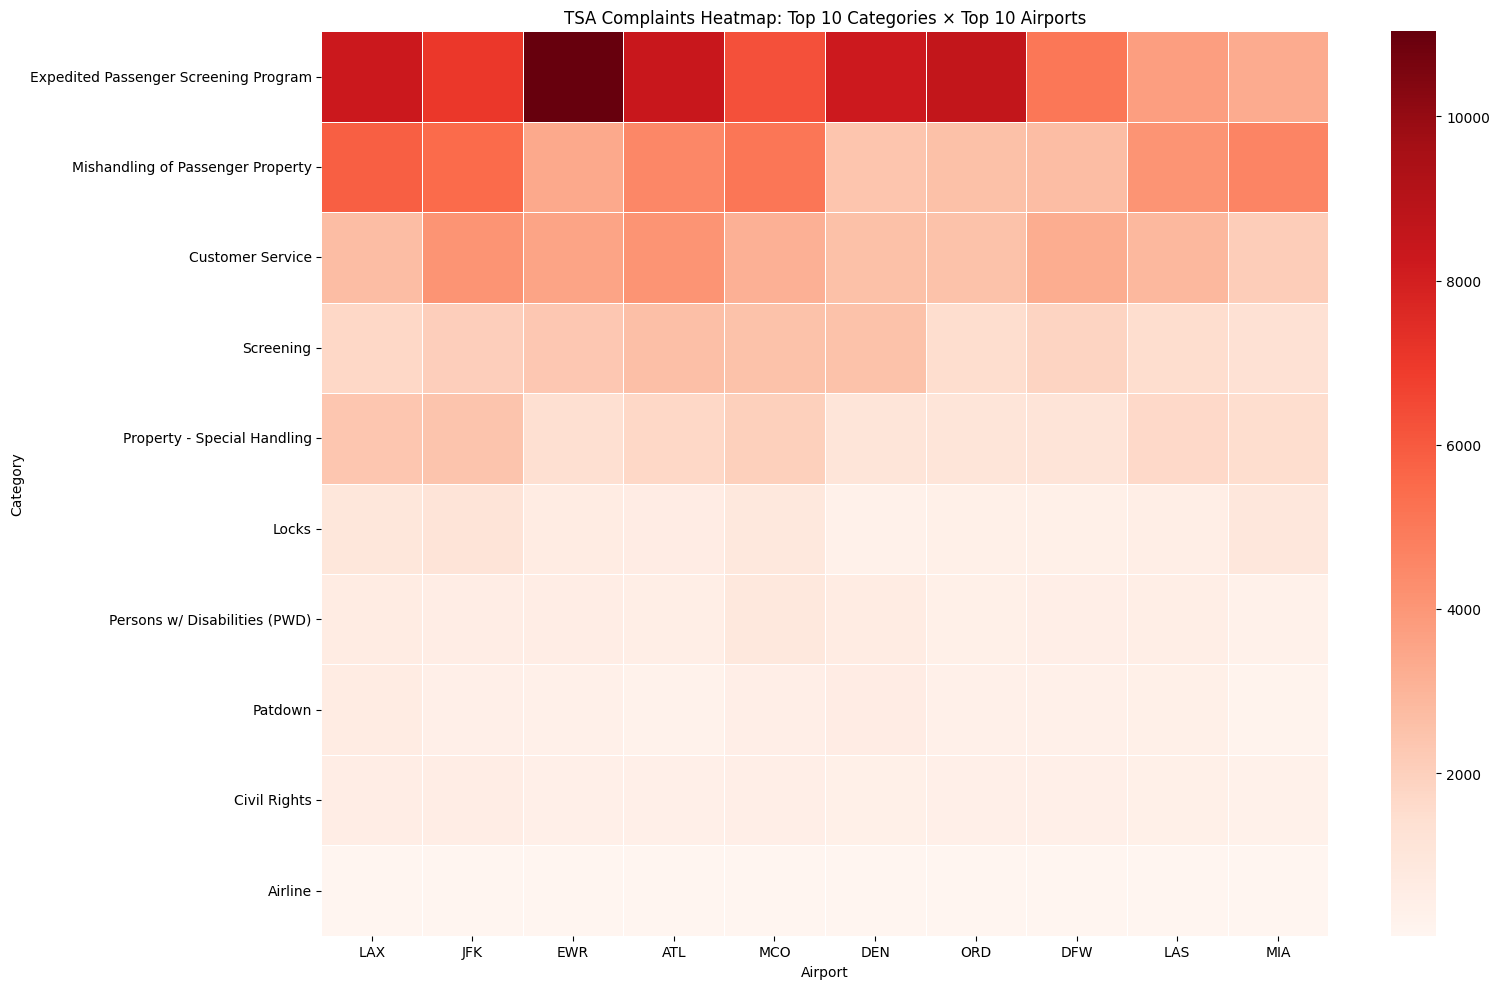

In [110]:
# ---- 1. Find top 10 airports ----
airport_totals = (
    iata_complaints_by_category_icao
    .groupby('airport')['count']
    .sum()
    .sort_values(ascending=False)
)

# We have to use the top 10 because smaller region airport only contribute a small amount of data

top_10_airports = airport_totals.head(10).index

# There are too many categories to visualize and most are 0 even for major airports like JFK, so we'll only take the top 10 categories.

# ---- 2. Find top 10 categories ----
category_totals = (
    iata_complaints_by_category_icao
    .groupby('category')['count']
    .sum()
    .sort_values(ascending=False)
)

top_10_categories = category_totals.head(10).index

# ---- 3. Filter original data to top airports & top categories ----
top_data = iata_complaints_by_category_icao[
    (iata_complaints_by_category_icao['airport'].isin(top_10_airports)) &
    (iata_complaints_by_category_icao['category'].isin(top_10_categories))
]

# ---- 4. Create heatmap matrix ----
heatmap_data = (
    top_data
    .groupby(['category', 'airport'])['count']
    .sum()
    .unstack(fill_value=0)
    .reindex(index=top_10_categories, columns=top_10_airports)
)

plt.figure(figsize=(16, 10))
sns.heatmap(heatmap_data, cmap='Reds', linewidths=0.5)
plt.title('TSA Complaints Heatmap: Top 10 Categories × Top 10 Airports')
plt.xlabel('Airport')
plt.ylabel('Category')
plt.tight_layout()
plt.show()


## Visualization 4 – Boxplot of Top Sub-Complaint Category
- **Data Source:** `complaints-by-subcategory.csv`  
- **Goal:** Display the distribution of counts for the most-frequent sub-complaint category, including outliers.

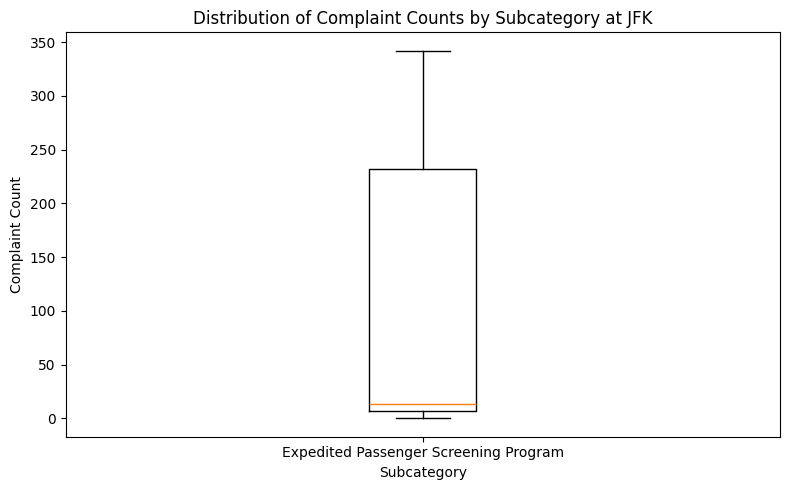

In [111]:
# Reassign to new variable to avoid modifying the original
df_sub = complaints_by_subcategory

# Filter for JFK only, as it has a high complaint count
df_jfk = df_sub[df_sub['airport'] == 'JFK']

# Filter for each subcategory of interest
subcats = [
    "Expedited Passenger Screening Program",
]

data = []
labels = []

for sub in subcats:
    counts = df_jfk[df_jfk['subcategory'] == sub]['count']
    if not counts.empty:
        data.append(counts)
        labels.append(sub)

plt.figure(figsize=(8, 5))

# Multiple boxplots on same chart
plt.boxplot(data, vert=True, labels=labels, showfliers=True)

plt.title("Distribution of Complaint Counts by Subcategory at JFK")
plt.ylabel("Complaint Count")
plt.xlabel("Subcategory")

plt.tight_layout()
plt.show()


## Visualization 5 – Bubble Chart of Top 10 Complaint Categories
- **Data Source:** `complaints-by-subcategory.csv`  
- **Goal:** Compare the scale of major complaint categories using bubble size to reflect complaint volume.

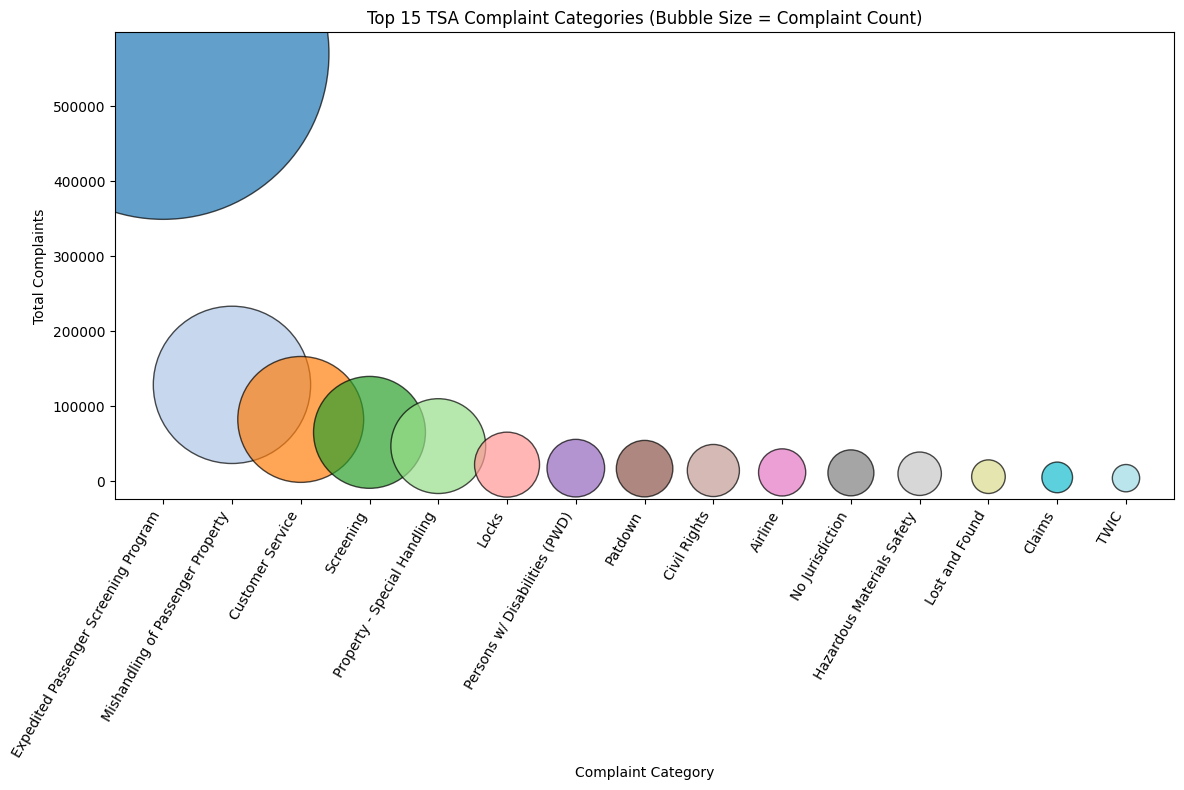

In [112]:
import matplotlib.pyplot as plt
import numpy as np

# Get the top 15 categories
top_15_categories = (
    iata_complaints_by_category_icao
    .groupby('category')['count']
    .sum()
    .sort_values(ascending=False)
    .head(15)
    .reset_index()
)

# Create a color list—one color per category
colors = plt.cm.tab20(np.linspace(0, 1, len(top_15_categories)))

plt.figure(figsize=(12, 8))

plt.scatter(
    x=top_15_categories['category'],
    y=top_15_categories['count'],
    s=top_15_categories['count'] / 10,  # scale bubble size
    alpha=0.7,
    color=colors,       # assign colors
    edgecolors='k'
)

plt.xticks(rotation=60, ha='right')
plt.title('Top 15 TSA Complaint Categories (Bubble Size = Complaint Count)')
plt.xlabel('Complaint Category')
plt.ylabel('Total Complaints')
plt.tight_layout()
plt.show()


## Visualization 6 – Line Chart of TSA Complaints Over Time
- **Data Source:** `complaints-by-subcategory.csv`  
- **Goal:** Plot complaint counts by month or year to reveal upward or downward trends in TSA complaints.

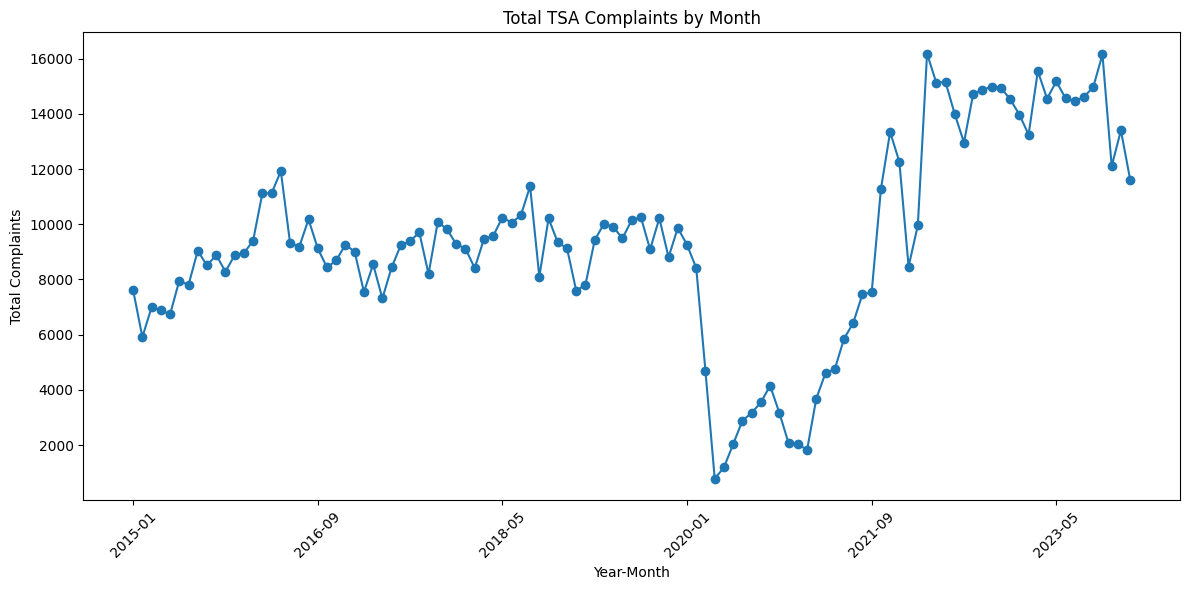

In [113]:
plt.figure(figsize=(12, 6))
complaints_by_subcategory.groupby('year_month')['count'].sum().plot(kind='line', marker='o')
plt.title('Total TSA Complaints by Month')
plt.xlabel('Year-Month')
plt.ylabel('Total Complaints')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()